Saving xe-ngoai-giao-1-1491701409882.webp to xe-ngoai-giao-1-1491701409882 (1).webp
Số xe: 5


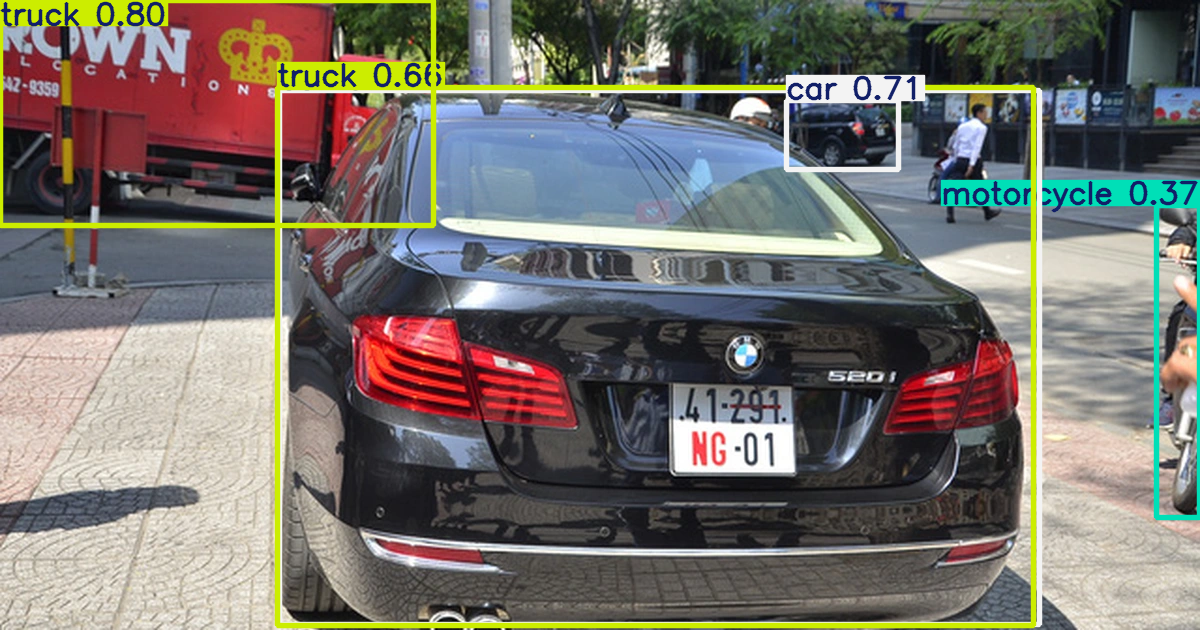

In [20]:
# CELL 1: Chọn ảnh và nhận diện xe
%pip install -q ultralytics

from ultralytics import YOLO
from google.colab import files
from google.colab.patches import cv2_imshow
from PIL import Image, ImageOps
from io import BytesIO
import numpy as np
import cv2

upload = files.upload()
if not upload:
    raise ValueError("Bạn chưa chọn ảnh. Hãy chạy lại cell này.")
anh_pil = Image.open(BytesIO(next(iter(upload.values()))))
anh = cv2.cvtColor(np.array(ImageOps.exif_transpose(anh_pil).convert("RGB")), cv2.COLOR_RGB2BGR)

model_xe = YOLO("yolov8n.pt")
kq_xe = model_xe(anh, classes=[2, 3, 5, 7], conf=0.25, verbose=False)[0]
print("Số xe:", len(kq_xe.boxes))
cv2_imshow(kq_xe.plot())


Số biển số: 1


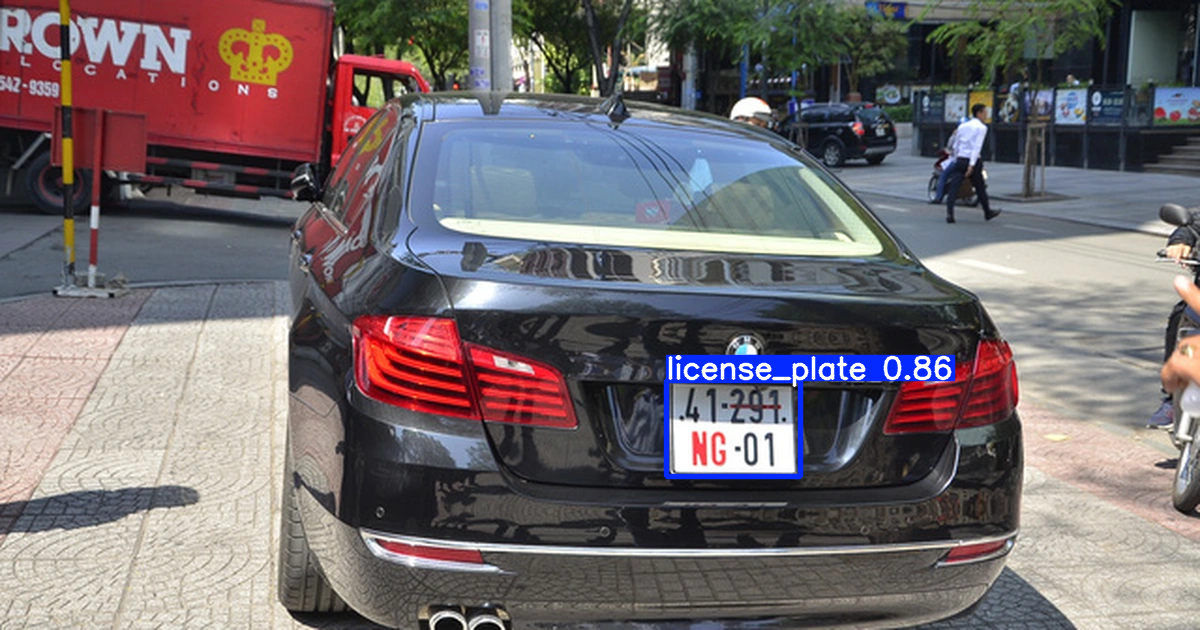

In [21]:
# CELL 2: Nhận diện vị trí biển số trên cùng ảnh
# Model: https://github.com/ddkhoa2605/LicensePlateDetection
from pathlib import Path
from urllib.request import urlretrieve

file_model = "DetectLisence_YOLO11.pt"
if not Path(file_model).exists():
    urlretrieve(
        "https://raw.githubusercontent.com/ddkhoa2605/LicensePlateDetection/main/DetectLisence_YOLO11.pt",
        file_model
    )

model_bien_so = YOLO(file_model)
kq_bien_so = model_bien_so(anh, conf=0.25, verbose=False)[0]
print("Số biển số:", len(kq_bien_so.boxes))
cv2_imshow(kq_bien_so.plot())


In [30]:
# CELL 3: Chọn ảnh hoặc video để chạy cả hai model
from google.colab import files
from google.colab.patches import cv2_imshow
from pathlib import Path
import cv2
import numpy as np

def nhan_dien(frame):
    kq_xe = model_xe(
        frame, classes=[2, 3, 5, 7], conf=0.25, verbose=False
    )[0]
    kq_bien_so = model_bien_so(
        frame, conf=0.25, verbose=False
    )[0]

    ket_qua = frame.copy()

    for kq, mau, la_bien_so in [
        (kq_xe, (0, 255, 0), False),
        (kq_bien_so, (0, 0, 255), True)
    ]:
        for box in kq.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            ten = "bien so" if la_bien_so else kq.names[int(box.cls.item())]

            cv2.rectangle(ket_qua, (x1, y1), (x2, y2), mau, 2)
            cv2.putText(
                ket_qua, f"{ten} {box.conf.item():.2f}",
                (x1, max(20, y1 - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, mau, 2
            )

    return ket_qua, kq_bien_so


loai = input("Nhập 1 để chọn ảnh, 2 để chọn video: ").strip()
if loai not in ("1", "2"):
    raise ValueError("Chỉ nhập 1 hoặc 2.")

upload = files.upload()
if not upload:
    raise ValueError("Bạn chưa chọn tệp.")

ten_file = next(iter(upload))
print("Xanh: xe | Đỏ: biển số")

if loai == "1":
    # Cập nhật anh và kq_bien_so để cell OCR tiếp tục dùng được
    anh = cv2.imdecode(
        np.frombuffer(upload[ten_file], dtype=np.uint8),
        cv2.IMREAD_COLOR
    )
    if anh is None:
        raise ValueError("Không đọc được ảnh.")

    anh_chung, kq_bien_so = nhan_dien(anh)
    cv2_imshow(anh_chung)

else:
    cap = cv2.VideoCapture(ten_file)
    if not cap.isOpened():
        raise ValueError("Không mở được video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        fps = 25

    tong_frame = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    thanh_cong, frame = cap.read()
    if not thanh_cong:
        cap.release()
        raise ValueError("Video không có khung hình đọc được.")

    h, w = frame.shape[:2]
    # Tên khác tệp đầu vào để không ghi đè video gốc
    dau_ra = str(Path(ten_file).with_name(
        Path(ten_file).stem + "_nhan_dien.mp4"
    ))

    writer = cv2.VideoWriter(
        dau_ra, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h)
    )
    if not writer.isOpened():
        cap.release()
        raise RuntimeError("Không tạo được video đầu ra.")

    dem = 0
    try:
        while thanh_cong:
            frame_ket_qua, _ = nhan_dien(frame)
            writer.write(frame_ket_qua)
            dem += 1

            if dem % 30 == 0:
                print(
                    f"\rĐã xử lý {dem}/{tong_frame} khung hình",
                    end=""
                )

            thanh_cong, frame = cap.read()
    finally:
        cap.release()
        writer.release()

    print(f"\nHoàn tất: {dau_ra}")
    files.download(dau_ra)


Nhập 1 để chọn ảnh, 2 để chọn video: 2


Saving traffic_video_original.mp4 to traffic_video_original.mp4
Xanh: xe | Đỏ: biển số
Đã xử lý 690/715 khung hình
Hoàn tất: traffic_video_original_nhan_dien.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import re
from google.colab import files

NGUONG = 0.90

def dinh_dang(text):
    # Chỉ thêm dấu nếu khớp mẫu; không sửa ký tự OCR
    mau = re.fullmatch(r"(\d{2}[A-Z](?:[A-Z]|\d)?)(\d{5})", text)
    if mau:
        dau, so = mau.groups()
        return f"{dau}-{so[:3]}.{so[3:]}"
    return text


def doc_bien_so(frame, hien_chi_tiet=False):
    ket_qua = frame.copy()
    boxes = model_bien_so(
        frame, conf=0.25, verbose=False
    )[0].boxes

    h, w = frame.shape[:2]

    if hien_chi_tiet and len(boxes) == 0:
        print("Không phát hiện biển số.")

    for i, box in enumerate(boxes, start=1):
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w, x2), min(h, y2)

        bien_so = frame[y1:y2, x1:x2]
        if bien_so.size == 0:
            continue

        rgb = cv2.cvtColor(bien_so, cv2.COLOR_BGR2RGB)
        du_doan = ocr_vn.run_one(rgb, return_confidence=True)
        text = du_doan.plate or ""

        diem = (
            np.asarray(du_doan.char_probs).reshape(-1)
            if du_doan.char_probs is not None
            else np.array([])
        )

        du_diem = bool(text) and len(diem) >= len(text)

        if du_diem:
            diem = diem[:len(text)]
            text_kiem_tra = "".join(
                ky_tu if np.isfinite(p) and p >= NGUONG else "?"
                for ky_tu, p in zip(text, diem)
            )
            dat_nguong = all(
                np.isfinite(p) and p >= NGUONG for p in diem
            )
        else:
            text_kiem_tra = "?" * len(text) if text else "Khong doc duoc"
            dat_nguong = False

        nhan = dinh_dang(text_kiem_tra)
        if not dat_nguong:
            nhan += " [kiem tra]"

        mau = (0, 255, 0) if dat_nguong else (0, 165, 255)

        cv2.rectangle(ket_qua, (x1, y1), (x2, y2), mau, 2)
        cv2.putText(
            ket_qua, nhan,
            (x1, max(20, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, mau, 2
        )

        if hien_chi_tiet:
            print(f"\nBiển số {i} — OCR gốc: {text}")
            print("Kết quả:", nhan)
            if du_diem:
                print(" | ".join(
                    f"{c}: {p:.2f}" for c, p in zip(text, diem)
                ))
            cv2_imshow(bien_so)

    return ket_qua


# Dùng lựa chọn loai và ten_file ở cell 3
if loai == "1":
    cv2_imshow(doc_bien_so(anh, hien_chi_tiet=True))

elif loai == "2":
    # Đọc lại video gốc, không OCR trên video đã vẽ khung
    cap = cv2.VideoCapture(ten_file)
    if not cap.isOpened():
        raise ValueError("Không mở được video gốc.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        fps = 25

    tong = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ok, frame = cap.read()
    if not ok:
        cap.release()
        raise ValueError("Không đọc được khung hình.")

    h, w = frame.shape[:2]
    dau_ra = str(Path(ten_file).with_name(
        Path(ten_file).stem + "_ocr.mp4"
    ))

    writer = cv2.VideoWriter(
        dau_ra, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h)
    )
    if not writer.isOpened():
        cap.release()
        raise RuntimeError("Không tạo được video đầu ra.")

    dem = 0
    try:
        while ok:
            frame_ocr = doc_bien_so(frame)
            writer.write(frame_ocr)
            dem += 1

            if dem % 30 == 0:
                print(f"\rĐã OCR {dem}/{tong} khung hình", end="")

            ok, frame = cap.read()
    finally:
        cap.release()
        writer.release()

    print(f"\nHoàn tất: {dau_ra}")
    files.download(dau_ra)

Đã OCR 690/715 khung hình
Hoàn tất: traffic_video_original_ocr.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving best_traffic_med_yolo_v8.pt to best_traffic_med_yolo_v8 (2).pt
Saving images (1).jpg to images (1).jpg


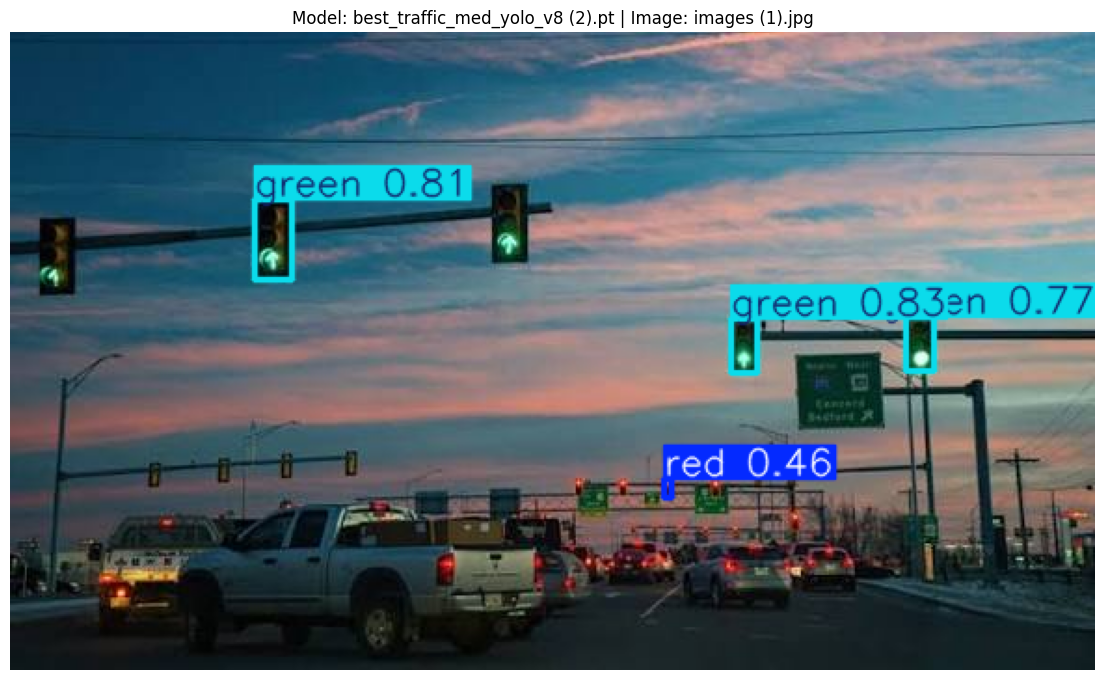

In [29]:
from google.colab import files
from ultralytics import YOLO
import matplotlib.pyplot as plt
import os

# 1. Upload model .pt + ảnh cần test
uploaded = files.upload()

# Tìm file model
model_file = next(
    filename for filename in uploaded
    if filename.lower().endswith(".pt")
)

# Tìm file ảnh
image_file = next(
    filename for filename in uploaded
    if filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
)

# 2. Load model
model = YOLO(f"/content/{model_file}")

# 3. Nhận diện ảnh
results = model.predict(
    source=f"/content/{image_file}",
    conf=0.25,
    imgsz=640,
    verbose=False
)

# 4. Hiển thị kết quả
result_img = results[0].plot()

plt.figure(figsize=(14, 9))
plt.imshow(result_img[..., ::-1])
plt.axis("off")
plt.title(f"Model: {model_file} | Image: {image_file}")
plt.show()